## Setup
計算用関数の定義

① xxzハミルトニアンのMPOを構築 \
xxz_hamiltonian_mpo(n_qubits: int, interaction: float = 1.0, anisotropy: float = 1.0)

② 量子状態のAnsatzを構築 \
ansatz は状態を生成するための回路の構造・形式。$|\psi_{\mathrm{HVA}}(\boldsymbol{\theta})\rangle$ はその ansatz で生成される状態。\
build_ground_state_ansatz(n_qubits: int, n_layers: int)

③ 基底状態を作る量子回路Ansatzを最適化 $|\psi_{\mathrm{HVA}}(\boldsymbol{\theta}^*)\rangle \approx |\psi_0\rangle$ \
optimize_ground_state_ansatz(
    ansatz: QuantumCircuit,
    x0: NDArray[np.floating],
    target_mps: qtn.MatrixProductState,
    *,
    max_bond: int | None = None,
    cutoff: float = 1e-10,
    method: str = "COBYQA",
    options: dict | None = None,
)

④ トロッター時間発展 $|\phi(t)\rangle=(e^{-iH\Delta t})^n|\phi(0)\rangle$ \
trotter_evolution(
    qubits: Sequence[Qubit],
    interaction: float,
    anisotropy: float,
    time_step: float,
    n_steps: int,
)

⑤ 遅延Green関数から動的構造因子を計算 \
get_dsf(
    n_qubits: int,
    rgf_mat: NDArray[np.floating],
    time_step: float,
    n_steps: int,
    n_points_momentum: int,
    n_points_frequency: int,
)
⑥ S(q,w)のヒートマップを描画 \
plot_dsf(
    dsf: NDArray[np.floating],
    time_step: float,
    n_points_momentum: int,
    n_points_frequency: int,
    title: str | None = None,
)

⑦ 遅延Green関数のヒートマップを描画 \
plot_rgf(
    n_qubits: int,
    rgf_mat: NDArray[np.floating],
    time_step: float,
    n_steps: int,
    title: str | None = None,
)

⑧ 2量子ビットゲートの深さを求め、回路の実行コストを評価 \
uniform_2q_depth(circuit: QuantumCircuit)

In [ ]:
import timeit
import warnings
from collections.abc import Iterator, Sequence
from functools import partial
import matplotlib.pyplot as plt
import numpy as np
import quimb.tensor as qtn
import scipy.optimize
from numpy.typing import NDArray
from qiskit import QuantumCircuit
from qiskit.circuit import CircuitInstruction, ParameterVector, Qubit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_addon_aqc_tensor import generate_ansatz_from_circuit
from qiskit_addon_aqc_tensor.objective import MaximizeStateFidelity
from qiskit_addon_aqc_tensor.simulation import tensornetwork_from_circuit
from qiskit_addon_aqc_tensor.simulation.quimb import QuimbSimulator
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_quimb import quimb_circuit
from scipy.sparse import SparseEfficiencyWarning

# scipy.sparse.linalg.expm (reached via PauliEvolutionGate.to_matrix) prefers
# CSC and warns when handed the CSR matrix from SparsePauliOp.to_matrix; the
# result is unaffected, so silence the cosmetic warning.　計算結果に影響しない警告を表示しない
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)

# XXZ Hamiltonian MPO ただし昇降演算子で記述
def xxz_hamiltonian_mpo(
    n_qubits: int, interaction: float = 1.0, anisotropy: float = 1.0
) -> qtn.MatrixProductOperator:
    """1D XXZ Hamiltonian as a quimb MPO.

    Builds the Hamiltonian using ``qtn.SpinHam1D``.

    Args:
        n_qubits: Number of sites.
        interaction: Overall interaction strength (J in the paper).
        anisotropy: XY/Z anisotropy (ε in the paper). ``ε = 1`` is the
            isotropic Heisenberg point; ``ε = 0`` is the Ising limit.

    Returns:
        The Hamiltonian as a matrix product operator.
    """
    builder = qtn.SpinHam1D(S=1 / 2)
    builder += interaction * anisotropy * 0.5, "+", "-"
    builder += interaction * anisotropy * 0.5, "-", "+"
    builder += interaction, "Z", "Z"
    return builder.build_mpo(L=n_qubits)

# DMRGで求めた基底状態を近似するためのパラメータ付き回路(HVA の量子回路)を構築する。
def build_ground_state_ansatz(n_qubits: int, n_layers: int) -> QuantumCircuit:
    """Hamiltonian variational ansatz (HVA) circuit for ground-state preparation.

    Starts from a product of singlet pairs and applies alternating
    odd/even layers of parameterized XXZ pair-evolution gates.

    The returned circuit is parameterized: it carries a ``ParameterVector``
    named ``"theta"`` of length ``2 * n_layers`` whose values must be
    assigned (e.g. via ``circuit.assign_parameters``) before simulation.
    Element ``2 * r`` is the odd-layer angle and element ``2 * r + 1`` is the
    even-layer angle of layer ``r``.

    Args:
        n_qubits: Number of qubits (must be even).
        n_layers: Number of HVA layers.

    Returns:
        The parameterized HVA preparation circuit.
    """
    theta = ParameterVector("theta", 2 * n_layers)
    circuit = QuantumCircuit(n_qubits)
    # Initial singlet product state
    for i in range(n_qubits // 2):
        circuit.x(2 * i)
        circuit.x(2 * i + 1)
        circuit.h(2 * i + 1)
        circuit.cx(2 * i + 1, 2 * i)
    # Variational layers: each pair gate is exp(-i theta (XX+YY+ZZ)/2)
    pair_ham = SparsePauliOp(
        ["XX", "YY", "ZZ"], coeffs=[0.5, 0.5, 0.5]
    )  # H_pair (HVA form)
    for r in range(n_layers):
        for i in range(1, (n_qubits + 1) // 2):  # odd layer
            circuit.append(
                PauliEvolutionGate(pair_ham, time=theta[2 * r]),
                [2 * i - 1, 2 * i],
            )
        for i in range(n_qubits // 2):  # even layer
            circuit.append(
                PauliEvolutionGate(pair_ham, time=theta[2 * r + 1]),
                [2 * i, 2 * i + 1],
            )
    return circuit

# 回路パラメータを最適化し、与えられた target_mps (DMRG の基底状態)に HVA の状態を近づける。
def optimize_ground_state_ansatz(
    ansatz: QuantumCircuit,
    x0: NDArray[np.floating],
    target_mps: qtn.MatrixProductState,
    *,
    max_bond: int | None = None,
    cutoff: float = 1e-10,
    method: str = "COBYQA",
    options: dict | None = None,
) -> scipy.optimize.OptimizeResult:
    """Optimize HVA parameters by maximizing fidelity with a target MPS.

    The HVA circuit is simulated as a matrix product state with the given
    bond-dimension truncation, and the parameters are optimized to maximize
    the state fidelity ``|<psi_HVA | target_mps>|**2`` with the DMRG ground
    state. Both states are normalized, so the minimized objective is the
    infidelity ``1 - |<psi_HVA | target_mps>|**2``.

    Args:
        ansatz: Parameterized HVA circuit from ``build_ground_state_ansatz``.
            The length of ``x0`` must equal ``ansatz.num_parameters``.
        x0: Initial parameters.
        target_mps: Target MPS (DMRG ground state) to maximize fidelity with.
        max_bond: Maximum MPS bond dimension during gate application.
        cutoff: Singular-value cutoff during gate application.
        method: ``scipy.optimize.minimize`` method.
        options: Options dict forwarded to ``scipy.optimize.minimize``.

    Returns:
        The Scipy OptimizeResult.
    """
    # パラメータを最適化するための目的関数
    def infidelity(params: NDArray[np.floating]) -> float:
        circuit = ansatz.assign_parameters(params)
        circuit_mps = quimb_circuit(
            circuit.decompose(["PauliEvolution"]),
            quimb_circuit_class=qtn.CircuitMPS,
            max_bond=max_bond,
            cutoff=cutoff,
        )
        return 1 - abs(circuit_mps.psi.H @ target_mps) ** 2
    # 目的関数が最小になるようにパラメータを最適化する
    return scipy.optimize.minimize(
        infidelity, np.asarray(x0), method=method, options=options
    )

# Trotter evolution of the XXZ Hamiltonian
def trotter_evolution(
    qubits: Sequence[Qubit],
    interaction: float,
    anisotropy: float,
    time_step: float,
    n_steps: int,
) -> Iterator[CircuitInstruction]:
    """Second-order Trotter steps of the XXZ pair Hamiltonian.

    While the paper used a hand-optimized circuit for the Trotter steps, we use
    PauliEvolutionGate here for simplicity and generality. The final two-qubit gate
    count and gate depth are equivalent when transpiled with ``optimization_level=3``.

    Args:
        qubits: Qubits to act on (length ``n_qubits``).
        interaction: Overall interaction strength (J in the paper).
        anisotropy: XY/Z anisotropy (ε in the paper). ``ε = 1`` is the
            isotropic Heisenberg point; ``ε = 0`` is the Ising limit.
        time_step: Per-step Trotter time.
        n_steps: Number of Trotter steps.

    Yields:
        ``CircuitInstruction``s implementing the Trotter steps.
    """
    if n_steps == 0:
        return
    n_qubits = len(qubits)
    pair_ham = SparsePauliOp(
        ["XX", "YY", "ZZ"],
        coeffs=[
            0.25 * interaction * anisotropy,
            0.25 * interaction * anisotropy,
            0.25 * interaction,
        ],
    )
    half_evo = PauliEvolutionGate(pair_ham, time=time_step / 2)
    full_evo = PauliEvolutionGate(pair_ham, time=time_step)
    for i in range(n_qubits // 2):  # half even layer
        yield CircuitInstruction(half_evo, (qubits[2 * i], qubits[2 * i + 1]))
    for i in range(n_qubits // 2 - 1):  # full odd layer
        yield CircuitInstruction(
            full_evo, (qubits[2 * i + 1], qubits[2 * i + 2])
        )
    for _ in range(n_steps - 1):  # interior steps
        for i in range(n_qubits // 2):
            yield CircuitInstruction(
                full_evo, (qubits[2 * i], qubits[2 * i + 1])
            )
        for i in range(n_qubits // 2 - 1):
            yield CircuitInstruction(
                full_evo, (qubits[2 * i + 1], qubits[2 * i + 2])
            )
    for i in range(n_qubits // 2):  # half even layer
        yield CircuitInstruction(half_evo, (qubits[2 * i], qubits[2 * i + 1]))

# 遅延Green 関数から動的構造因子を計算	Fourier 変換などの後処理
def get_dsf(
    n_qubits: int,
    rgf_mat: NDArray[np.floating],
    time_step: float,
    n_steps: int,
    n_points_momentum: int,
    n_points_frequency: int,
) -> NDArray[np.floating]:
    """Compute the dynamical structure factor from the retarded Green's function.

    Uses the center-site approximation and a discrete Fourier transform.
    The result is symmetrized about the momentum axis and clipped to
    non-negative values, ready for plotting.

    Args:
        n_qubits: Number of qubits (sites).
        rgf_mat: RGF matrix of shape ``(n_steps, n_qubits)``.
        time_step: Trotter time-step size.
        n_steps: Number of time steps.
        n_points_momentum: Number of momentum points.
        n_points_frequency: Number of frequency points.

    Returns:
        DSF array of shape ``(n_points_frequency, n_points_momentum)``,
        symmetrized about the momentum axis and clipped to non-negative values.
    """
    max_frequency = np.pi / time_step
    momentum_range = np.linspace(0, 2 * np.pi, n_points_momentum)
    frequency_range = np.linspace(0, max_frequency, n_points_frequency)
    result = np.zeros((frequency_range.shape[0], momentum_range.shape[0]))
    center = n_qubits // 2 - 1
    for iw, w in enumerate(frequency_range):
        exponent = np.exp(1j * w * time_step * np.arange(1, n_steps + 1))
        # S = sigma/2, so two spin operators contribute a factor of (1/2)(1/2) = 1/4.
        rgf_omega = (
            np.dot(rgf_mat.T, exponent) * time_step / 4
        )  # S(omega): time Fourier slice of the Green's function
        for iq, q in enumerate(momentum_range):
            momentum_phases = np.exp(
                -1j * q * np.arange(-center, center + 2, 1)
            )
            result[iw, iq] = np.imag(np.dot(rgf_omega, momentum_phases))
    result = -(result + result[:, ::-1]) / 2
    result = np.clip(result, a_min=0, a_max=None)
    return result

# S(q,w)のヒートマップを描画
def plot_dsf(
    dsf: NDArray[np.floating],
    time_step: float,
    n_points_momentum: int,
    n_points_frequency: int,
    title: str | None = None,
) -> None:
    """Heat-map of the dynamical structure factor.

    Args:
        dsf: DSF array of shape ``(n_points_frequency, n_points_momentum)``.
        time_step: Trotter time-step size.
        n_points_momentum: Number of momentum points.
        n_points_frequency: Number of frequency points.
        title: Optional plot title.
    """
    max_frequency = np.pi / time_step
    momentum_range = np.linspace(0, 2 * np.pi, n_points_momentum)
    frequency_range = np.linspace(0, max_frequency, n_points_frequency)
    x, y = np.meshgrid(momentum_range, frequency_range)
    fig, ax = plt.subplots(figsize=(8, 5))
    c = ax.pcolormesh(x, y, dsf / np.max(dsf), cmap="viridis", shading="auto")
    fig.colorbar(c, ax=ax, label="Normalized intensity")
    ax.set_ylim(0, 3.6)
    ax.set_xlim(0, 2 * np.pi)
    ax.set_xlabel(r"$q$", fontsize=16)
    ax.set_ylabel(r"$\tilde{\omega} = \omega / J$", fontsize=16)
    ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
    ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
    if title:
        ax.set_title(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# 遅延Green関数のヒートマップを描画
def plot_rgf(
    n_qubits: int,
    rgf_mat: NDArray[np.floating],
    time_step: float,
    n_steps: int,
    title: str | None = None,
) -> None:
    """Heat-map of the retarded Green's function in real space and time.

    Args:
        n_qubits: Number of qubits (sites).
        rgf_mat: RGF matrix of shape ``(n_steps, n_qubits)``.
        time_step: Trotter time-step size.
        n_steps: Number of time steps.
        title: Optional plot title.
    """
    fig, ax = plt.subplots(figsize=(8, 6))
    qubit_axis = np.arange(n_qubits)
    t_axis = np.arange(1, n_steps + 1) * time_step
    x, y = np.meshgrid(qubit_axis, t_axis)
    c = ax.pcolormesh(
        x,
        y,
        np.real(rgf_mat),
        cmap="RdBu",
        vmax=0.5,
        vmin=-0.5,
        shading="auto",
    )
    fig.colorbar(c, ax=ax, label=r"Re $G^R(j, j_c, t)$")
    ax.set_xlabel("Qubit", fontsize=16)
    ax.xaxis.set_major_locator(
        plt.matplotlib.ticker.MaxNLocator(integer=True)
    )
    ax.set_ylabel(r"Time", fontsize=16)
    if title:
        ax.set_title(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# 2量子ビットゲートの深さを求め、回路の実行コストを評価
def uniform_2q_depth(circuit: QuantumCircuit) -> int:
    """Two-qubit gate depth in a standardized basis."""
    pass_manager = generate_preset_pass_manager(
        optimization_level=0, basis_gates=["cz", "id", "rz", "sx", "x"]
    )
    return pass_manager.run(circuit).depth(
        lambda inst: inst.operation.num_qubits == 2
    )

## Small-scale simulator example

10量子ビット。まず小規模な系で手法を検証する。

Step 1 — Map classical inputs to a quantum problem
ハミルトニアンを定義し、DMRGで基底状態を計算。HVA回路を最適化して、摂動とTrotter時間発展の回路を作る。

Step 2 — Optimize problem for quantum hardware execution
AQCで深い回路を圧縮し、短い回路に置き換える。

Step 3 — Execute using Qiskit primitives
回路を実行して、各サイトの $\langle \sigma_i^z\rangle$ を求める。この小規模例では状態ベクトルシミュレータを使う。

Step 4 — Post-process and return result in desired classical format
測定結果から遅延グリーン関数 $\langle G^R(j,j_c,t)\rangle$ を構成し、フーリエ変換して動的構造因子 $S(q,\omega)$ を得る。

### Step 1: Map classical inputs to a quantum problem

1. **モデルの定義**  
   1D spin-1/2 Heisenberg model のハミルトニアンを定義する。

2. **基底状態の計算と量子回路で準備**  
   DMRG / MPS を用いてreference基底状態 $|\psi_0\rangle$ を求める。

   この基底状態を、量子回路ansatzで実現したい。まず初期状態を、隣接サイトごとのシングレット状態の積として準備する。その後、ハミルトニアンに基づくゲート
   $$U_{\mathrm{pair}}(\theta)=e^{-i\theta H_{\mathrm{pair}}},    H_{pair} = J/4 (XX+YY+ZZ)$$

   を複数層作用させ、HVA回路の状態 $|\psi_{\mathrm{HVA}}(\boldsymbol{\theta})\rangle$ を得る。DMRGで求めた基底状態 $|\psi_0\rangle$ との忠実度$F(\boldsymbol{\theta})=\left|\langle\psi_0|\psi_{\mathrm{HVA}}(\boldsymbol{\theta})\rangle\right|^2$
   が最大となるようにパラメータ $\boldsymbol{\theta}$ を最適化し、基底状態を近似的に再現する。$|\psi_{\mathrm{HVA}}(\boldsymbol{\theta}^*)\rangle \approx |\psi_0\rangle$

3. **局所摂動と時間発展**

   中央サイト $c$ に摂動(回転ゲート $R^z(\pi/2)$ )を加え、摂動後の初期状態

   $$|\phi(0)\rangle=R^Z_c(\pi/2)|\psi_{\mathrm{HVA}}(\boldsymbol{\theta}^*)\rangle$$

   を準備する。2次の Trotter 分解を用いて、時間発展を量子回路として構成する。
   $$|\phi(t)\rangle=(e^{-iH\Delta t})^n|\phi(0)\rangle$$

   ** Step1では、AQCによる回路圧縮は行わず、深い回路をそのまま実行する。Step2でAQCによる回路圧縮を行う。

In [ ]:
# -- Physical parameters --
n_qubits = 10
interaction = 1.0  # J
anisotropy = 1.0  # ε (isotropic point)
time_step = 0.6
n_steps = 10
mps_max_bond = 32
mps_cutoff = 1e-8
center = n_qubits // 2 - 1

# -- Hamiltonian MPO --
ham_mpo = xxz_hamiltonian_mpo(n_qubits, interaction, anisotropy)

# -- Reference ground-state energy via DMRG --
dmrg = qtn.DMRG2(ham_mpo)
dmrg.solve(tol=1e-8,verbosity=1) 
print(f"Ground-state energy (DMRG): {dmrg.energy:.6f}")

# -- Build ground state ansatz circuit --
gs_n_layers = 3
gs_ansatz = build_ground_state_ansatz(n_qubits, gs_n_layers)

# -- 最適化Optimize ground state ansatz parameters to maximize fidelity with the DMRG MPS --
# Initialize odd-layer angles near 0 (where the inter-pair gate is the
# identity) and even-layer angles near pi/2 (where the intra-pair gate
# is a SWAP, since 0.5*(XX + YY + ZZ) = SWAP - I/2).
rng = np.random.default_rng(12345)
x0 = np.tile([0, np.pi / 2], gs_n_layers) + rng.normal(scale=0.1, size=2 * gs_n_layers)  # パラメタベクトルθ
# - 標準偏差 \(0.1\) の正規分布から乱数を6個生成する。- 2つを足して、初期値を基準値の近くに少しずつずらす。
print("Optimizing ground state ansatz...")
t0 = timeit.default_timer()
# 最適化
result = optimize_ground_state_ansatz(
    gs_ansatz,
    x0,
    dmrg.state,
    max_bond=mps_max_bond,
    cutoff=mps_cutoff,
    options=dict(maxiter=100),
)
t1 = timeit.default_timer()
print(f"Finished optimizing ground state ansatz in {t1 - t0} seconds.")
print(f"Ground state ansatz fidelity: {1 - result.fun:.6f}")        # 1に近いほど忠実度が高い

# 最適化したパラメータで回路を構築し、基底状態のエネルギーを計算する。
gs_circuit = gs_ansatz.assign_parameters(result.x)
gs_circuit_mps = quimb_circuit(
    gs_circuit.decompose(["PauliEvolution"]),
    quimb_circuit_class=qtn.CircuitMPS,
    max_bond=mps_max_bond,
    cutoff=mps_cutoff,
)
gs_ansatz_energy = qtn.expec_TN_1D(
    gs_circuit_mps.psi.H, ham_mpo, gs_circuit_mps.psi
)
print(f"Ground state ansatz energy: {gs_ansatz_energy:.6f}")

##　ここまでで基底状態の準備が完了。次に局所摂動を加えて時間発展を行う。


# -- 中心にRzの摂動を加えた状態 --
perturbed = gs_circuit.copy()
perturbed.rz(np.pi / 2, center)

# t = 1,2,  についてtrotter時間発展
circuits = []
for t in range(1, n_steps + 1):
    circuit = perturbed.copy()
    for instr in trotter_evolution(
        circuit.qubits, interaction, anisotropy, time_step, t
    ):
        circuit.append(instr)
    circuits.append(circuit)
print(
    f"Built {len(circuits)} circuits, deepest 2q depth (uniform basis) = "
    f"{uniform_2q_depth(circuits[-1])}"
)

# -- Observables: Z on each qubit site --
observables = [
    SparsePauliOp.from_sparse_list([("Z", [i], 1)], num_qubits=n_qubits)
    for i in range(n_qubits)
]
print(f"Defined {len(observables)} Z observables.")

1, R, max_bond=(8/8), cutoff:1e-08


100%|#############################################| 9/9 [00:01<00:00,  6.06it/s]

Energy: -4.2577717411701155 ... not converged.
2, R, max_bond=(8/16), cutoff:1e-08



100%|############################################| 9/9 [00:00<00:00, 599.56it/s]

Energy: -4.258035182705146 ... not converged.
3, R, max_bond=(16/32), cutoff:1e-08



100%|############################################| 9/9 [00:00<00:00, 783.36it/s]

Energy: -4.258035183372957 ... converged!


Ground-state energy (DMRG): -4.258035
Optimizing ground state ansatz...
Finished optimizing ground state ansatz in 5.845634582976345 seconds.
Ground state ansatz fidelity: 0.984196
Ground state ansatz energy: -4.231867
Built 10 circuits, deepest 2q depth (uniform basis) = 163
Defined 10 Z observables.


### Step2: Optimize problem for quantum hardware execution

Step1で構築したTrotter時間発展の回路を、AQCによって、パラメータ付き回路で近似・圧縮する。

AQCでは、元の回路が生成する目標状態 $|\psi_{\mathrm{target}}\rangle$ と圧縮後の状態 $|\psi_{\mathrm{AQC}}(\boldsymbol{\theta})\rangle$ の忠実度が最大となるようにパラメータを最適化する。

このコードでは、最初の3ステップをone-layer ansatz でまとめて近似、次の2ステップをtwo-layer ansatz でまとめて近似。残りの5ステップは通常の Trotter 回路をそのまま使う。

2a: 圧縮対象となる元の回路を選ぶ \
2b: 元の回路を MPS として古典シミュレーションする \
2c: 短い ansatz のパラメータを最適化する \
2d: 圧縮した回路と通常の Trotter 回路を組み合わせる

最後の結果から、circuit depthが減らせたことがわかる。


Step 2b — target MPS:
  k=1: max bond = 22
  k=2: max bond = 22
  k=3: max bond = 26
  k=4: max bond = 27
  k=5: max bond = 29

Step 2c — one-layer ansatz: 389 parameters, 2q depth (uniform basis) = 27
Step 2c — two-layer ansatz: 470 parameters, 2q depth (uniform basis) = 33
  k=1: fidelity = 1.0000, 2q depth (uniform basis) = 27, 4.1s
  k=2: fidelity = 0.9977, 2q depth (uniform basis) = 27, 4.6s
  k=3: fidelity = 0.9947, 2q depth (uniform basis) = 27, 4.5s
  k=4: fidelity = 0.9981, 2q depth (uniform basis) = 33, 5.5s
  k=5: fidelity = 0.9951, 2q depth (uniform basis) = 33, 5.9s

Step 2d — assembled 10 circuits
  At step 10 (uniform basis): Trotter 2q depth = 163, AQC+Trotter 2q depth = 99; 2q gates: Trotter = 371, AQC+Trotter = 200


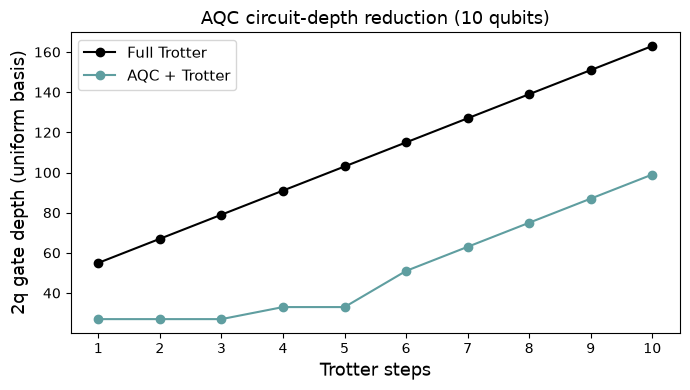

In [ ]:
# Number of time steps to compress into an AQC ansatz with one layer
aqc_n_steps_1 = 3
# Number of time steps to compress into an AQC ansatz with two layers
aqc_n_steps_2 = 2
aqc_n_steps_total = aqc_n_steps_1 + aqc_n_steps_2

# ── Step 2a: Target circuits (first aqc_n_steps_total circuits from Step 1) ──
target_circuits = {
    k: circuits[k - 1] for k in range(1, aqc_n_steps_total + 1)
}
# ── Step 2b: Compute target MPS ──
# Decompose PauliEvolutionGate to RXX/RYY/RZZ before passing to the AQC MPS
# backend, which does not understand PauliEvolutionGate natively.
aqc_sim = QuimbSimulator(
    quimb_circuit_factory=partial(
        qtn.CircuitMPS,
        gate_opts=dict(max_bond=mps_max_bond, cutoff=mps_cutoff),
    ),
    autodiff_backend="jax",
)
print("\nStep 2b — target MPS:")
target_mps = {}
for k in range(1, aqc_n_steps_total + 1):
    target_mps[k] = tensornetwork_from_circuit(
        target_circuits[k].decompose(["PauliEvolution"]), aqc_sim
    )
    print(f"  k={k}: max bond = {target_mps[k].psi.max_bond()}")

# ── Step 2c: Generate ansätze (one-layer and two-layer) and optimize parameters ──
# でもどんなansatzが生成されるのかはよくわからない汗。generate_ansatz_from_circuitの実装に依存。
ansatz_1, initial_params_1 = generate_ansatz_from_circuit(
    target_circuits[1].decompose(["PauliEvolution"]),
    qubits_initially_zero=True,
)
initial_params_1 = np.array(initial_params_1)
s
ansatz_2, initial_params_2 = generate_ansatz_from_circuit(
    target_circuits[2].decompose(["PauliEvolution"]),
    qubits_initially_zero=True,
)
initial_params_2 = np.array(initial_params_2)
print(
    f"\nStep 2c — one-layer ansatz: {ansatz_1.num_parameters} parameters, "
    f"2q depth (uniform basis) = {uniform_2q_depth(ansatz_1)}"
)
print(
    f"Step 2c — two-layer ansatz: {ansatz_2.num_parameters} parameters, "
    f"2q depth (uniform basis) = {uniform_2q_depth(ansatz_2)}"
)

aqc_circuits = {}
aqc_params = {}
for k in range(1, aqc_n_steps_total + 1):
    if k <= aqc_n_steps_1:
        ansatz, base_params = ansatz_1, initial_params_1
    else:
        ansatz, base_params = ansatz_2, initial_params_2
    # Warm-start from the previous step only within the same stage
    same_stage = (k - 1 >= 1) and (
        (k - 1 <= aqc_n_steps_1) == (k <= aqc_n_steps_1)
    )
    x0 = aqc_params[k - 1] if same_stage else base_params
    obj = MaximizeStateFidelity(target_mps[k], ansatz, aqc_sim)
    t0 = timeit.default_timer()
    result = scipy.optimize.minimize(
        obj.loss_function,
        x0,
        method="L-BFGS-B",
        jac=True,
        options=dict(maxiter=100),
    )
    elapsed = timeit.default_timer() - t0
    aqc_params[k] = result.x
    aqc_circuits[k] = ansatz.assign_parameters(result.x)
    print(
        f"  k={k}: fidelity = {1 - result.fun:.4f}, "
        f"2q depth (uniform basis) = "
        f"{uniform_2q_depth(aqc_circuits[k])}, "
        f"{elapsed:.1f}s"
    )

# ── Step 2d: Assemble full circuit set (AQC + Trotter) ──
all_circuits = []
for k in range(1, aqc_n_steps_total + 1):
    all_circuits.append(aqc_circuits[k])
base = aqc_circuits[aqc_n_steps_total]
for k in range(1, n_steps - aqc_n_steps_total + 1):
    circuit = base.copy()
    for instr in trotter_evolution(
        circuit.qubits, interaction, anisotropy, time_step, k
    ):
        circuit.append(instr)
    all_circuits.append(circuit)

full_depths = [
    uniform_2q_depth(circuits[k - 1]) for k in range(1, n_steps + 1)
]
aqc_depths = [uniform_2q_depth(circuit) for circuit in all_circuits]
full_2q = [
    circuits[k - 1].decompose(["PauliEvolution"]).num_nonlocal_gates()
    for k in range(1, n_steps + 1)
]
aqc_2q = [
    circuit.decompose(["PauliEvolution"]).num_nonlocal_gates()
    for circuit in all_circuits
]
print(f"\nStep 2d — assembled {len(all_circuits)} circuits")
print(
    f"  At step {n_steps} (uniform basis): "
    f"Trotter 2q depth = {full_depths[-1]}, AQC+Trotter 2q depth = {aqc_depths[-1]}; "
    f"2q gates: Trotter = {full_2q[-1]}, AQC+Trotter = {aqc_2q[-1]}"
)

steps_axis = np.arange(1, n_steps + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps_axis, full_depths, "-o", color="black", label="Full Trotter")
ax.plot(
    steps_axis, aqc_depths, "-o", color="cadetblue", label="AQC + Trotter"
)
ax.set_xlabel("Trotter steps", fontsize=13)
ax.xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
ax.set_ylabel("2q gate depth (uniform basis)", fontsize=13)
ax.set_title(f"AQC circuit-depth reduction ({n_qubits} qubits)", fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Step 3: Execute using Qiskit primitives

We simulate each AQC-compiled circuit using the StatevectorEstimator primitive.

回路を実行して、各サイトの $\langle \sigma_i^z\rangle$ を求める。この小規模例では状態ベクトルシミュレータを使う。

In [ ]:
estimator = StatevectorEstimator()          # 回路の状態をシミュレーションし、各演算子の期待値を求める
pubs = [(circuit, observables) for circuit in all_circuits]
job = estimator.run(pubs)
result = job.result()

print(result[0].data)

PrimitiveResult([PubResult(data=DataBin(evs=np.ndarray(<shape=(10,), dtype=float64>), stds=np.ndarray(<shape=(10,), dtype=float64>), shape=(10,)), metadata={'target_precision': 0.0, 'circuit_metadata': {}}), PubResult(data=DataBin(evs=np.ndarray(<shape=(10,), dtype=float64>), stds=np.ndarray(<shape=(10,), dtype=float64>), shape=(10,)), metadata={'target_precision': 0.0, 'circuit_metadata': {}}), PubResult(data=DataBin(evs=np.ndarray(<shape=(10,), dtype=float64>), stds=np.ndarray(<shape=(10,), dtype=float64>), shape=(10,)), metadata={'target_precision': 0.0, 'circuit_metadata': {}}), PubResult(data=DataBin(evs=np.ndarray(<shape=(10,), dtype=float64>), stds=np.ndarray(<shape=(10,), dtype=float64>), shape=(10,)), metadata={'target_precision': 0.0, 'circuit_metadata': {}}), PubResult(data=DataBin(evs=np.ndarray(<shape=(10,), dtype=float64>), stds=np.ndarray(<shape=(10,), dtype=float64>), shape=(10,)), metadata={'target_precision': 0.0, 'circuit_metadata': {}}), PubResult(data=DataBin(evs=n